# Shape the tumor

In this tutorial we change the tumor through its configuration.
We start from `tutorial_config.yaml`, the tumor of the [Quickstart](01_quickstart.ipynb), change one or two values at a time and compare the runs by their tissue maps, clone dynamics and copy number.
The sections cover selection, the mutation process, the architecture of the tissue, selection by the niche, the metastatic site and treatment.
Every parameter is a key of one of the parameter blocks of [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/), whose page documents them all.

Each run uses the same evolution seed.
A change to the proportion of genes with a role, a key starting with `prop_`, also moves the genes of the other roles.
Such a run is therefore a different tumor, and not only the same tumor with one value changed.
Most runs stop at 8,000 cancer cells, and the sections on invasion and the metastatic site grow to 16,000 and 25,000 cells.
The notebook runs in about 45 minutes on a laptop.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from iscc import pregrown
from iscc.constants import normal_names
from iscc.integrations import biological_types, clones_from_clades
from iscc.treatment import Chemotherapy
from iscc.tumor import GenotypeTumor
from iscc.tumor.viz import CNV_CMAP, cnv_norm

A parameter block passed to [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) next to `config` is merged into the block of the configuration key by key, so a run changes only the values it names.
`grow` builds the tutorial tumor with the blocks it is given and grows it to a number of cancer cells, or for at most `max_generations` generations.
`cancer_cells` builds the per-cell tables of every cancer cell, restricted to the demes that contain cancer cells, so that the tables stay small.

In [2]:
def grow(target_cancer=8000, max_generations=600, seed=7, **blocks):
    """The tutorial tumor with the parameter blocks `blocks` merged in, grown to `target_cancer` cancer cells."""
    tumor = GenotypeTumor(config="tutorial_config.yaml", seed=seed, **blocks)
    tumor.grow(n_steps=int(max_generations / tumor.tau), target_cancer=target_cancer, materialize=False)
    return tumor


def cancer_cells(tumor, layers=()):
    """Per-cell tables of every cancer cell of the tumor."""
    region = [i for i, deme in enumerate(tumor.demes) if set(deme) - set(normal_names)]
    cells = tumor.make_cell_data(region=region, max_cells=10**6, layers=list(layers))
    keep = biological_types(cells["cell_type"]["cell_id"]) == "cancer"
    return {name: table[keep] for name, table in cells.items()}

## Selection

The division rate of a cancer cell follows the dosage model of CINner.
`prop_driver` (0.04) sets the share of genes that are oncogenes or tumor suppressor genes (TSGs), and `driver_effects` (1.03) the effect of one copy.
Each mutated or gained copy of an oncogene, and each mutated or lost copy of a TSG, multiplies the division rate by about `driver_effects`, up to `max_birth_rate` (2.0).
With `driver_effects` at 1, the drivers are neutral and the driver clones change by drift alone, and larger values give each driver a larger advantage.
We grow the tumor with the three values and show its driver clones over time.

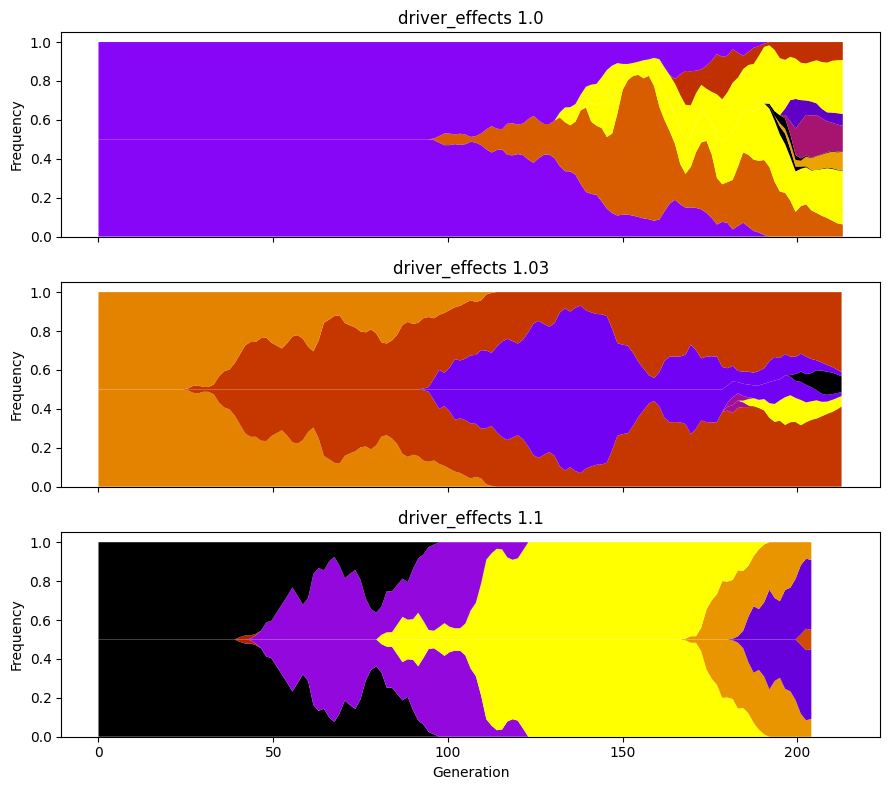

driver_effects 1.0: 213 generations, mean division rate 0.70, mean mutated drivers per cell 1.6
driver_effects 1.03: 213 generations, mean division rate 0.74, mean mutated drivers per cell 1.4
driver_effects 1.1: 205 generations, mean division rate 1.92, mean mutated drivers per cell 4.9


In [3]:
selection = {value: grow(selection_params={"driver_effects": value}) for value in (1.0, 1.03, 1.1)}

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, (value, tumor) in zip(axes, selection.items()):
    tumor.plot_muller(ax=ax, by_drivers=True, min_freq=0.05)
    ax.set_title(f"driver_effects {value}")
for ax in axes[:-1]:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

for value, tumor in selection.items():
    evo = cancer_cells(tumor)["cell_evo"]
    print(f"driver_effects {value}: {tumor.time:.0f} generations, mean division rate {evo['division_rate'].mean():.2f}, "
          f"mean mutated drivers per cell {(evo['n_mut_onc'] + evo['n_mut_tsg']).mean():.1f}")

With neutral drivers, the founder kept the whole tumor for about 100 generations, after which driver clones drifted to most of it, and the mean division rate stays at the baseline of 0.7 per generation.
At 1.03 and 1.1, driver clones replace one another in successive sweeps, faster at 1.1.
The mean division rate rises to 0.74 and 1.92 per generation, with 1.4 and 4.9 mutated drivers per cell on average.
At 1.1 the rate is higher than the mutated drivers alone give, about 1.12, since a copy number change of a segment also changes the dosage of every driver on it, and it is close to the ceiling of 2.0.

## Copy number, point mutations and genome doubling

A dividing cancer cell mutates with probability `mutation_rate` (0.15).
A mutation is a whole-genome doubling (WGD) with probability `wgd_rate` (0.01), and otherwise a copy number change of one segment or a point-mutation event, in proportion to `cnv_prob` and `snv_prob`.
A copy number change duplicates one copy of a segment with probability `amp_prob` and deletes it otherwise, and a point-mutation event adds a Poisson number of mutations with mean `n_snvs_per_allele` (0.1) to every copy of every segment.
The configuration sets `subtype: ER+`, which sets `cnv_prob` to 0.045 against the default `snv_prob` of 0.5, so about one mutation in twelve changes copy number.
`subtype: TNBC` is the other preset, and a value written in the configuration takes precedence over the preset.
A daughter cell whose genome would have a segment at zero copies is not viable (`max_nullisomy` 0, a key of `selection_params`).

We compare the tutorial tumor with a tumor at `cnv_prob` 0.3 by the copy number of every cancer cell, with the cells ordered by clone.

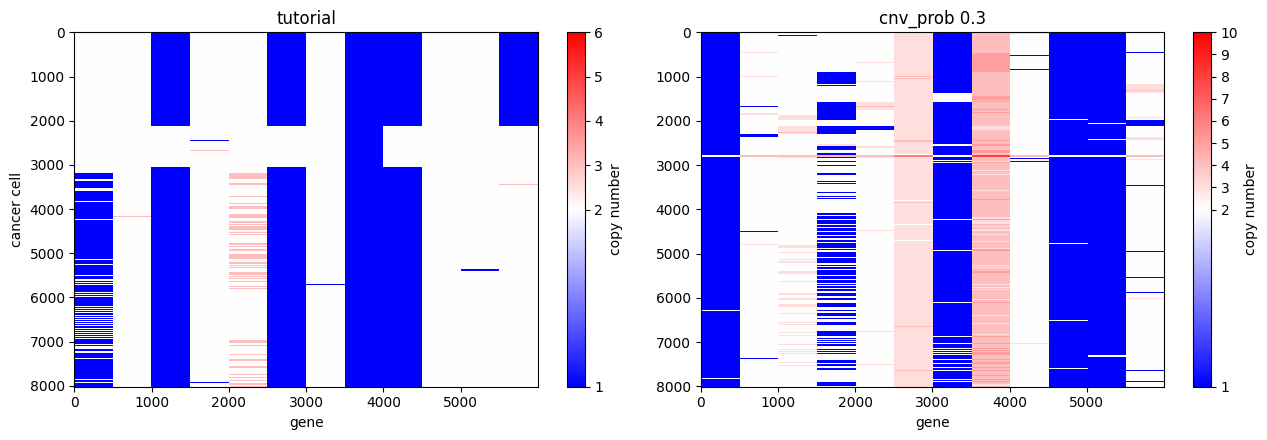

In [4]:
def plot_copy_number(tumor, ax, title):
    cells = cancer_cells(tumor, layers=["cell_cnv"])
    clones = clones_from_clades(tumor, min_cells=20, cell_ids=cells["cell_type"].index)
    cnv = cells["cell_cnv"].loc[clones.sort_values(kind="stable").index].values
    im = ax.imshow(cnv, aspect="auto", cmap=CNV_CMAP, norm=cnv_norm(cnv), interpolation="none")
    ax.set_title(title)
    ax.set_xlabel("gene")
    plt.colorbar(im, ax=ax, label="copy number")


genome = {"tutorial": selection[1.03], "cnv_prob 0.3": grow(cancer_cell_params={"cnv_prob": 0.3})}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (label, tumor) in zip(axes, genome.items()):
    plot_copy_number(tumor, ax, label)
axes[0].set_ylabel("cancer cell")
plt.tight_layout()
plt.show()

Both tumors carry copy number losses shared by most of their cells, and further changes that differ between clones.
At `cnv_prob` 0.3 more segments are altered, with gains of up to 10 copies, and in both tumors no segment has fewer than one copy.

We then raise `wgd_rate` to 0.1 and `n_snvs_per_allele` to 0.5, one at a time, and compare the ploidy, the mean copy number of each cancer cell, and the number of genes with a point mutation in each cancer cell.

tutorial: 0% of cancer cells doubled their genome


wgd_rate 0.1: 34% of cancer cells doubled their genome


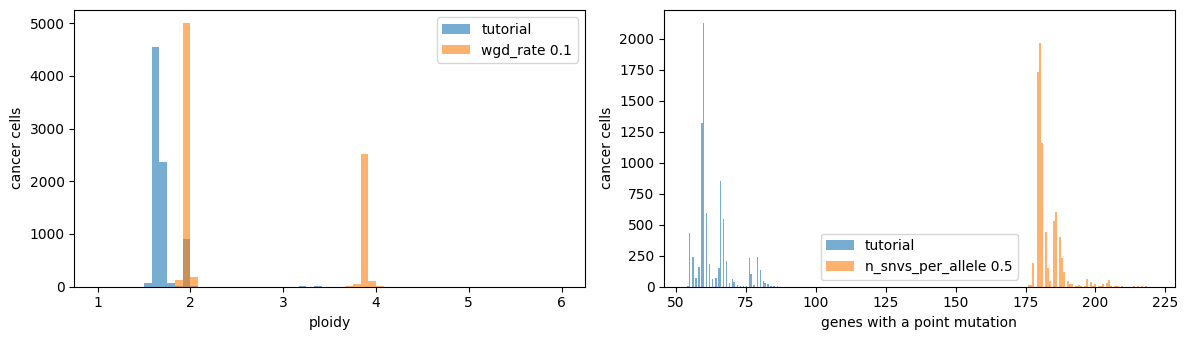

In [5]:
genome["wgd_rate 0.1"] = grow(cancer_cell_params={"wgd_rate": 0.1})
genome["n_snvs_per_allele 0.5"] = grow(cancer_cell_params={"n_snvs_per_allele": 0.5})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for label in ("tutorial", "wgd_rate 0.1"):
    cells = cancer_cells(genome[label], layers=["cell_cnv"])
    axes[0].hist(cells["cell_cnv"].mean(axis=1), bins=60, range=(1, 6), alpha=0.6, label=label)
    print(f"{label}: {cells['cell_wgd']['is_wgd'].mean():.0%} of cancer cells doubled their genome")
for label in ("tutorial", "n_snvs_per_allele 0.5"):
    cells = cancer_cells(genome[label], layers=["cell_snv"])
    axes[1].hist((cells["cell_snv"] > 0).sum(axis=1), bins=60, alpha=0.6, label=label)
axes[0].set_xlabel("ploidy")
axes[1].set_xlabel("genes with a point mutation")
for ax in axes:
    ax.set_ylabel("cancer cells")
    ax.legend()
plt.tight_layout()
plt.show()

At the tutorial `wgd_rate`, fewer than 1% of the cancer cells doubled their genome, the few cells at a ploidy above 3, and most cancer cells have a ploidy of about 1.7, since most of their copy number changes are losses.
At a `wgd_rate` of 0.1, 34% of the cancer cells doubled their genome and form the group at a ploidy of about 3.9.
Raising `n_snvs_per_allele` from 0.1 to 0.5 raises the number of genes with a point mutation from about 55 to 85 per cell to about 175 to 220.

## Architecture of the tissue

The ductal field places `n_glands` (5) glands of radius `gland_radius` (4 demes), at least `min_gland_sep` (13) demes apart, in a stroma that `stroma_fill_frac` (0.3) fills to a share of its capacity.
The carrying capacity of a gland deme is `K_duct` (60) cells, and that of a stroma deme is `K_stroma` (30).
With `structure_radius` at 0 there are no glands and no stroma, and the tumor grows from the center of an empty field whose demes have a carrying capacity of `carrying_capacity` (30) cells.
Each division sends one daughter to a neighboring deme with probability `dispersal_rate` (0.9).
The stroma also holds immune cells (below). In free growth we leave them out (`immune_density` 0), since in open tissue they would surround the founder and kill it before any clone could resist them, whereas in the ductal field the founder starts in a lumen without immune cells.
We grow the tumor in the ductal field and in free growth, and in free growth also at a `dispersal_rate` of 0.1.

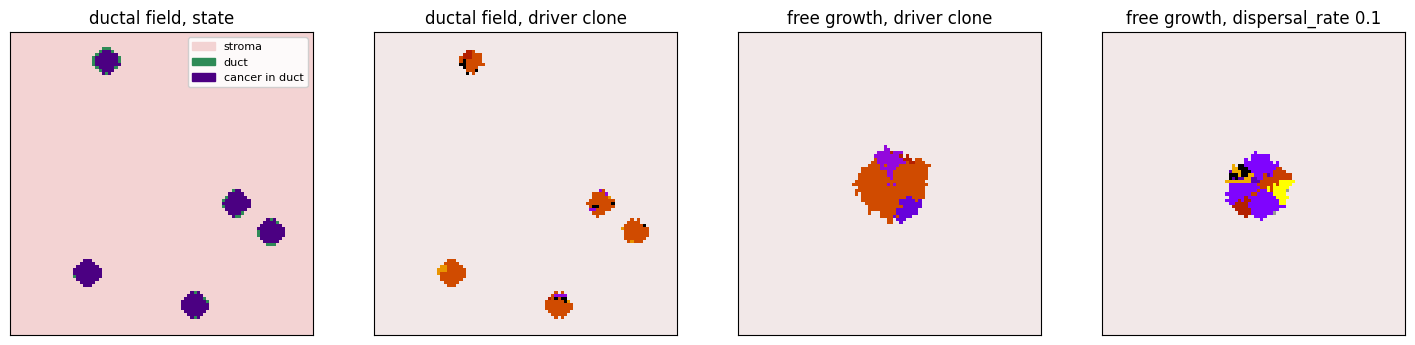

ductal field: 8,021 cancer cells after 213 generations
free growth: 8,008 cancer cells after 211 generations
free growth, dispersal_rate 0.1: 8,007 cancer cells after 229 generations


In [6]:
architecture = {
    "ductal field": selection[1.03],
    "free growth": grow(spatial_params={"structure_radius": 0, "immune_density": 0.0}),
    "free growth, dispersal_rate 0.1": grow(spatial_params={"structure_radius": 0, "immune_density": 0.0},
                                            cancer_cell_params={"dispersal_rate": 0.1}),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
architecture["ductal field"].plot_tissue(ax=axes[0], color="state")
for ax, label in zip(axes[1:], architecture):
    architecture[label].plot_tissue(ax=ax, color="clone", min_freq=0.02)
for ax, title in zip(axes, ["ductal field, state", "ductal field, driver clone", "free growth, driver clone",
                            "free growth, dispersal_rate 0.1"]):
    ax.set_title(title)
plt.show()
for label, tumor in architecture.items():
    print(f"{label}: {tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations")

In the ductal field the tumor fills the five glands and has not yet reached the stroma, and one driver clone dominates every gland.
In free growth the tumor is a compact disk in which one driver clone dominates and a second one occupies sectors at its edge.
At a `dispersal_rate` of 0.1 the tumor took 18 more generations to reach the same size, and more driver clones occupy sectors of their own.

The glands are connected by the intraductal route.
A daughter that leaves a gland jumps to the lumen of another gland with probability kappa / (1 + kappa), where kappa is `cross_gland_kappa` (0.06), and `cross_gland_lambda` (30 demes) sets the length of the distance kernel of the jump.
We switch the route off, and we shorten the kernel to 5 demes.

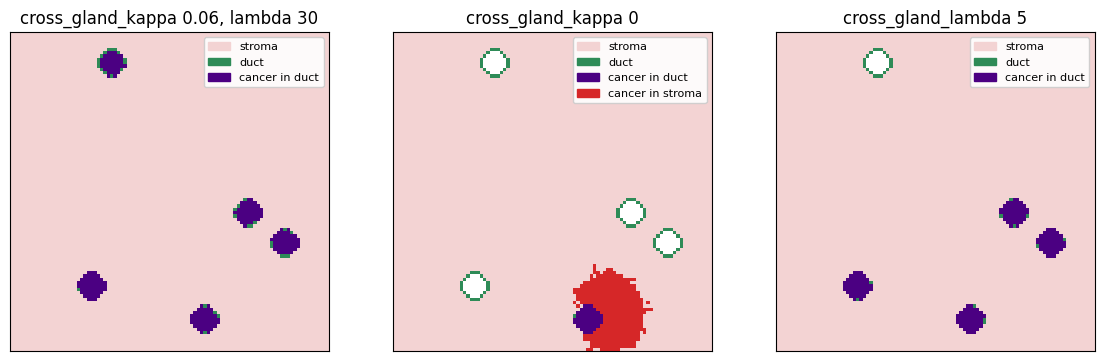

cross_gland_kappa 0.06, lambda 30: 8,021 cancer cells after 213 generations
cross_gland_kappa 0: 8,003 cancer cells after 429 generations
cross_gland_lambda 5: 8,009 cancer cells after 213 generations


In [7]:
spread = {
    "cross_gland_kappa 0.06, lambda 30": selection[1.03],
    "cross_gland_kappa 0": grow(spatial_params={"cross_gland_kappa": 0.0}),
    "cross_gland_lambda 5": grow(spatial_params={"cross_gland_lambda": 5}),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (label, tumor) in zip(axes, spread.items()):
    tumor.plot_tissue(ax=ax, color="state")
    ax.set_title(label)
plt.show()
for label, tumor in spread.items():
    print(f"{label}: {tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations")

Without the intraductal route, the tumor stays in its founding gland, from which it invades the stroma, and reaches 8,000 cancer cells only after 429 generations.
With a kernel of 5 demes, the tumor colonizes the four glands closest to one another, while the distant gland at the top has no cancer cells.

## Selection by the niche

Two traits decide whether cancer cells leave the glands and survive in the stroma.
With `breach_gated_invasion`, a daughter that leaves a gland for the stroma crosses with a probability equal to the breach level of the clone, and stays in the gland otherwise.
In the stroma, resident stromal cells add the death hazard `stromal_hazard` (0.9) times the stromal fraction of the deme times one minus the stromal survival level of the clone.
`prop_breach` and `prop_stromal_survival` (0.002 each) set the share of genes that carry each trait, and `breach_effects` (1.01) and `stromal_survival_effects` (4.0) the effect of a mutated copy.
`breach_cost` (0.6) and `stromal_survival_cost` (0.05) set the fraction of division that each trait costs per unit, wherever it is carried.

We grow the tutorial tumor to 16,000 cancer cells, and the same tumor without the gate and without the stromal hazard.
For each run we report the share of cancer cells in the stroma and the mean levels of the two traits in the cancer cells of the glands and of the stroma.

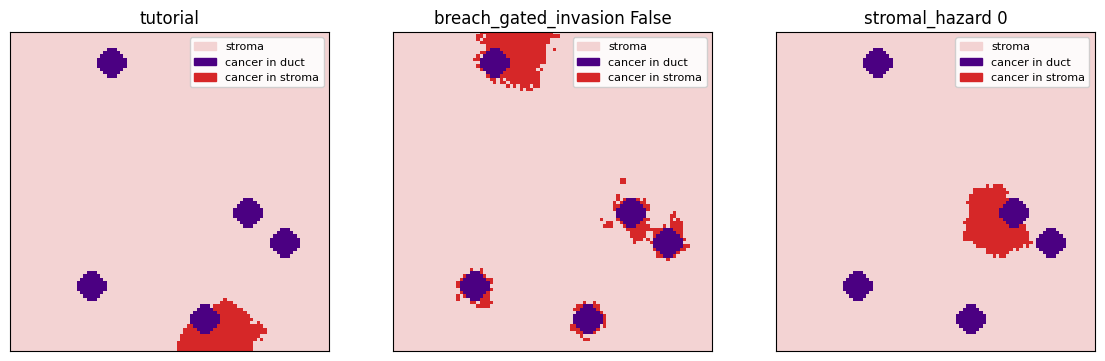

,generations,share in stroma,breach in gland,stromal_survival in gland,breach in stroma,stromal_survival in stroma
tutorial,589.0,0.238,0.001,0.003,0.010,0.000
breach_gated_invasion False,273.0,0.251,0.000,0.007,0.000,0.002
stromal_hazard 0,461.0,0.244,0.001,0.007,0.011,0.004


In [8]:
niche = {
    "tutorial": grow(target_cancer=16_000),
    "breach_gated_invasion False": grow(target_cancer=16_000, spatial_params={"breach_gated_invasion": False}),
    "stromal_hazard 0": grow(target_cancer=16_000, spatial_params={"stromal_hazard": 0.0}),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (label, tumor) in zip(axes, niche.items()):
    tumor.plot_tissue(ax=ax, color="state")
    ax.set_title(label)
plt.show()

rows = {}
for label, tumor in niche.items():
    cells = cancer_cells(tumor)
    place = np.where(cells["cell_gland"]["gland_id"] >= 0, "gland", "stroma")
    traits = cells["cell_evo"][["breach", "stromal_survival"]].groupby(place).mean()
    rows[label] = {"generations": round(tumor.time), "share in stroma": (place == "stroma").mean(),
                   **{f"{trait} in {where}": traits.loc[where, trait] for where in traits.index for trait in traits}}
pd.DataFrame(rows).T.round(3)

The tutorial tumor invaded the stroma from one gland and reached 16,000 cells after 589 generations.
Without the gate, cancer cells invaded the stroma around every gland, and the tumor reached the same size after 273 generations.
Without the stromal hazard, the tumor invaded the stroma from another gland and reached the same size after 461 generations.

With the gate, the cancer cells in the stroma carry breach at a mean level of 0.010 against 0.001 in the glands, as expected from the selection of breach at the gate.
Stromal survival stays at a mean level of at most 0.007 in the three runs, in the stroma as in the glands.
One run cannot separate selection by the niche from the history of the clones, and a study of niche selection should compare several seeds.

## Immune cells

The tutorial configuration seeds static immune cells in the stroma, `immune_density` (0.2) of the capacity of each stroma deme, and none in the ducts (`immune_duct_density` 0, the default).
The immune cells of each deme split into T and NK cells, myeloid cells, and B and plasma cells, with the shares of `immune_composition` (0.575, 0.315 and 0.11, those of the tumors of a breast cancer atlas).
They neither divide nor move, and a cancer birth that leaves a deme above its capacity pushes one immune cell out of the deme (`immune_displaceable`), so that nests of cancer cells lose their immune cells.
Only the T and NK cells kill: a cancer cell dies at `prob_kill` (28, under `cell_params.immune`) times the share of T and NK cells in the deme of the cell times one minus the immune resistance of the clone.
Immune resistance is a trait like breach: `prop_immune_resistance` (0.002) of the genes confer it, and one mutated copy gives a level of 0.75 (`immune_resistant_effects` 4.0).
The density of T and NK cells around a cancer cell also drives the interferon-response program of the cell (`niche_program_map`), which changes expression only.
We grow the tutorial tumor of the niche section again without immune killing (`prob_kill` 0) and compare the time to grow and the immune resistance of the cancer cells.

In [9]:
immune = {"prob_kill 28": niche["tutorial"], "prob_kill 0": grow(target_cancer=16_000, immune_cell_params={"prob_kill": 0.0})}
for label, tumor in immune.items():
    evo = cancer_cells(tumor)["cell_evo"]
    print(f"{label}: {tumor.time:.0f} generations, mean immune resistance {evo['immune_resistance'].mean():.2f}, "
          f"{(evo['immune_resistance'] > 0).mean():.0%} of cancer cells resistant")

prob_kill 28: 589 generations, mean immune resistance 0.37, 42% of cancer cells resistant


prob_kill 0: 279 generations, mean immune resistance 0.02, 2% of cancer cells resistant


With immune killing, the tumor took 589 generations to reach 16,000 cancer cells, against 279 without.
42% of its cancer cells carry immune resistance, at a mean level of 0.37, against 2% without killing, as expected from the selection of resistance by immune killing.

## The metastatic site

`met_grid_size` sets the side of a second lattice of host tissue, the metastatic site, which is off at 0.
The carrying capacity of its demes is `K_met` (60) cells, and `host_fill_frac` (0.5) of it is seeded with host cells.
A fraction kappa_m / (1 + kappa_m) of the daughters that leave a stroma deme of the primary are sent to the site, where kappa_m is `met_seed_kappa` (0.03).
The probability of surviving the transit is f + (1 - f) m, where f is `met_transit_floor` (0.001) and m the metastatic survival level of the clone.
At the site, the host cells add the death hazard `met_hazard` (3.5) times the host fraction of the deme times 1 - m.
The configuration already sets the metastatic survival trait (`prop_met_survival` 0.015, `met_survival_effects` 3.0, `met_survival_cost` 0.15), which costs division in the primary and pays off only at the site.
We switch the site on with a lattice as large as the primary and grow to 25,000 cancer cells.
`plot_muller_compartments` shows the clones of the primary and of the metastasis in shared colors, with the clones grouped by their mutated drivers and trait genes.

25,040 cancer cells after 665 generations, 960 of them at the metastatic site
cells placed at the site by seeding: 68
            mean metastatic survival  share with the trait
metastasis                     0.664                 1.000
primary                        0.028                 0.043


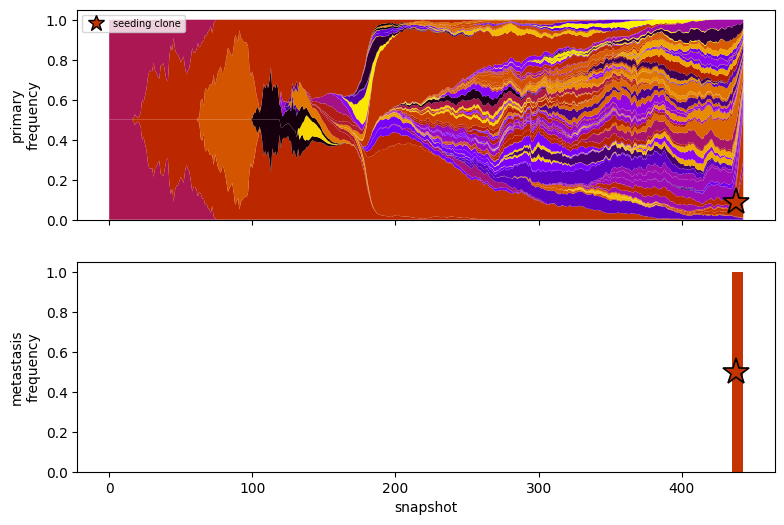

In [10]:
met = grow(target_cancer=25_000, max_generations=1500, spatial_params={"met_grid_size": 96})
cells = cancer_cells(met)
site = np.where(cells["cell_compartment"]["compartment"] == 1, "metastasis", "primary")
print(f"{met.get_cancer_size():,} cancer cells after {met.time:.0f} generations, {(site == 'metastasis').sum():,} of them at the metastatic site")
print(f"cells placed at the site by seeding: {sum(e['n'] for e in met.events if e.get('event') == 'seeding')}")
print(cells["cell_evo"]["met_survival"].groupby(site).agg(["mean", lambda m: (m > 0).mean()])
      .set_axis(["mean metastatic survival", "share with the trait"], axis=1).round(3))

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
met.plot_muller_compartments(axes=axes, by_drivers=True, min_freq=0.02, normalize=True)
plt.show()

Seeding placed 68 cells at the site, which now contains 960 of the 25,040 cancer cells.
Every cancer cell at the site carries metastatic survival, at a mean level of 0.66, against 4.3% of the cancer cells of the primary, as expected from the selection of the trait by the host hazard.
The metastasis appears only in the last records of the run, and it consists of the clone that the star marks in both panels, the clone of the first seeding cell.
The horizontal axis of this plot counts the records of the run, one every 1.5 generations.

## Treatment

A therapy acts during growth, through `GenotypeTumor.grow(treatment=...)`.
[`Chemotherapy`](https://pedrofale.github.io/iscc/reference/Chemotherapy/) adds a death hazard to every cancer cell while it is dosed, scaled down by the treatment resistance of the clone.
With `kill_mode="proliferation"`, the hazard is `kill_rate` times the division rate of the clone, so at `kill_rate` 1 a sensitive clone shrinks at the death rate of the clone whatever the division rate.
`toxicity` is the share of the dose that normal cells take.
`start` and `duration` are counted in steps of the run, each of `tau` (0.5) generations.
The other therapies and the shared dosing parameters are on the page of [`Treatment`](https://pedrofale.github.io/iscc/reference/Treatment/).

Resistance arises by mutation in the treatment-resistance genes.
`tutorial_config.yaml` sets no resistance genes (`prop_treatment_resistance` 0), so we add the resistance genes of the landing animation, rare (`prop_treatment_resistance` 0.001) and strong (`treatment_resistant_effects` 2.8), at a cost of 0.3 of division per unit of resistance (`treatment_resistance_cost`).
The package default of `prop_treatment_resistance`, 0.1, would make a tenth of all genes resistance genes, so that untreated cells reach high resistance through passenger mutations alone.
We grow the tumor to 12,000 cancer cells, give a course of 20 generations and follow the tumor for 10 generations after it.

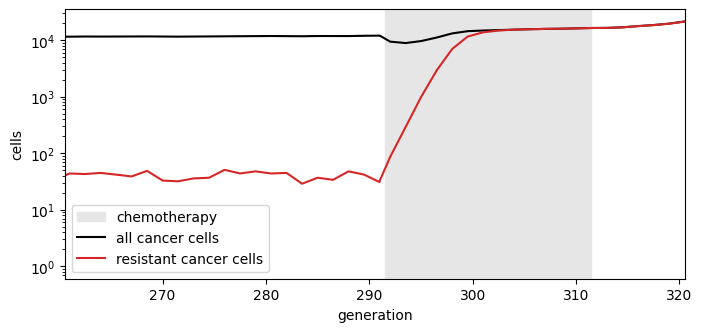

generation 291: 12,014 cancer cells, 33 resistant
generation 312: 16,391 cancer cells, 16,390 resistant
generation 321: 21,373 cancer cells, 21,247 resistant


In [11]:
resistance = {"prop_treatment_resistance": 0.001, "treatment_resistant_effects": 2.8, "treatment_resistance_cost": 0.3}
treated = grow(target_cancer=12_000, selection_params=resistance)
start = treated.step
chemo = Chemotherapy(start=start, duration=40, kill_rate=0.9, kill_mode="proliferation", effectiveness=1.0, toxicity=0.12)
treated.grow(n_steps=60, treatment=chemo, materialize=False)

def cancer_count(counts, resistant=False):
    return sum(n for g, n in counts.items() if g not in normal_names
               and (not resistant or treated.genotypes[g].evolutionary_parameters["treatment_resistance"] > 0))

time = np.array(treated.trace_times)
total = [cancer_count(tr["genotypes_counts"]) for tr in treated.traces]
resistant = [cancer_count(tr["genotypes_counts"], resistant=True) for tr in treated.traces]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axvspan(start * treated.tau, (start + 40) * treated.tau, color="0.9", label="chemotherapy")
ax.plot(time, total, color="k", label="all cancer cells")
ax.plot(time, resistant, color="tab:red", label="resistant cancer cells")
ax.set_yscale("log")
ax.set_xlim(time[-1] - 60, time[-1])
ax.set_xlabel("generation")
ax.set_ylabel("cells")
ax.legend()
plt.show()
for g in (start * treated.tau, (start + 40) * treated.tau, time[-1]):
    i = int(np.argmin(abs(time - g)))
    print(f"generation {time[i]:.0f}: {total[i]:,} cancer cells, {resistant[i]:,} resistant")

With the rare resistance genes, 33 of the 12,014 cancer cells were resistant when the course started.
The number of cancer cells fell at the start of the course and recovered within about five generations, as the resistant cells expanded under the drug and made up 16,390 of the 16,391 cancer cells at the end of the course.
In the 10 generations after the course, the tumor grew to 21,373 cancer cells, of which 21,247 are resistant, so the sensitive cells regrew only from the few that survived the drug.
`kill_rate` and `duration` set the depth and the length of the response of the sensitive cells, and `treatment_resistance_cost` sets how strongly the resistant cells lose against the sensitive cells without the drug.

## Tumors to start from

The module `iscc.pregrown` provides five tumors of 200,000 cancer cells, grown once on the 1 cm field of the paper (170 by 170 demes, eight glands) and downloaded on first use, to generate data from without growing ([pregrown tumors](https://pedrofale.github.io/iscc/reference/#pregrown-tumors)).
`ductal` is the tumor of the paper's regime without immune cells, and the other four grow with the immune cells of the regime.
`immune` is the regime itself, `neutral` grows without selection, with immune cells that kill nothing, `sweeps` has fewer and stronger drivers, and `cin` has four times the copy number events and five times the genome doubling of the paper's regime.
We show each one by its driver clones.

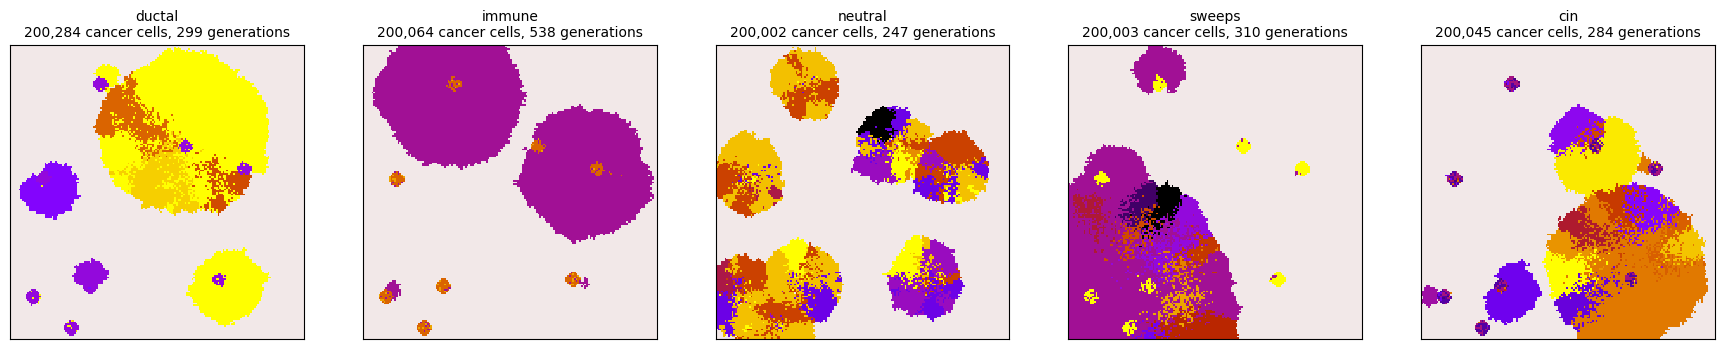

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, name in zip(axes, ("ductal", "immune", "neutral", "sweeps", "cin")):
    tumor = getattr(pregrown, name)()
    tumor.plot_tissue(ax=ax, color="clone")
    ax.set_title(f"{name}\n{tumor.get_cancer_size():,} cancer cells, {tumor.time:.0f} generations", fontsize=10)
    del tumor
plt.show()

The ductal tumor has one large invasive lesion shared by two driver clones, smaller invasive lesions and small tumors in situ in other glands.
In the immune tumor one driver clone dominates each of the two large lesions, and the other glands hold small tumors in situ.
The neutral tumor forms six lesions, each a mosaic of driver clones.
The sweeps tumor grew mostly in one large lesion, through which a late driver clone swept, and the lesions of the cin tumor each contain several driver clones.

## Next steps

[Shape the data](03_shape_the_data.ipynb) changes the assays that measure the tumor, and [Simulate a cohort](04_cohort.ipynb) grows many patients over one configuration.